# Proyecto Primer Parcial — Aporte individual

**Estudiante:** Caroline Yomaira Puya Gómez  
**Grupo:** D  
**Paralelo:** CDDEIA-ELNO-4-2  
**Responsabilidad:** Análisis exploratorio (EDA)  
**Dataset:** `student-mat.csv` (395 estudiantes)

**Nota:** Este notebook es una base completa y ejecutable de la sección asignada. Revísala, realiza tus cambios reales y registra el commit desde tu propia cuenta. No presentes como propio trabajo que no hayas revisado y comprendido.

## Preparación común para ejecutar de forma independiente
Estas celdas de configuración y carga de datos son compartidas como apoyo técnico; la sección atribuible a este integrante comienza más abajo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, confusion_matrix)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

SEMILLA = 2026
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
print('Bibliotecas cargadas; semilla:', SEMILLA)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-s92lzh5d because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas cargadas; semilla: 2026


In [2]:
# Lectura local: en Google Colab también funciona si el CSV se sube al panel Archivos.
rutas = [Path('student-mat.csv'), Path('data/student-mat.csv'), Path('/content/student-mat.csv')]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Coloca student-mat.csv junto al notebook o en data/. No se modificó el dataset.')
df_original = pd.read_csv(ruta_csv, sep=',')
assert df_original.shape == (395, 33), f'Se esperaban 395 filas y 33 columnas, recibido: {df_original.shape}'
assert {'G1','G2','G3','absences','studytime'}.issubset(df_original.columns)
print('Archivo:', ruta_csv, '| Filas:', df_original.shape[0], '| Columnas:', df_original.shape[1])
display(df_original.head())

Archivo: student-mat.csv | Filas: 395 | Columnas: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## Trabajo asignado: Análisis exploratorio (EDA)

**Revisión personal:** Revisar estadísticos, distribuciones de G3, failures, studytime y absences. Añadir observaciones propias y comprobar los tres hallazgos.

## Parte 1 — Análisis exploratorio (EDA)
**Responsables sugeridas:** Caroline Puya (EDA y gráficos) y Angy Soto (correlaciones y hallazgos). Se parte de la exploración que Caroline ya agregó en GitHub; este notebook organiza los resultados para cumplir todos los apartados de la rúbrica.

In [3]:
print('Estructura y tipos de datos:')
df_original.info()
print('\nResumen numérico:')
display(df_original.describe().T.round(2))
print('\nResumen de categorías:')
display(df_original.describe(include='object').T)
print('\nValores faltantes:', int(df_original.isna().sum().sum()), '| Duplicados exactos:', int(df_original.duplicated().sum()))
print('Promedio G3:', round(df_original.G3.mean(), 2), '| Aprobados (G3 >= 10):', round((df_original.G3 >= 10).mean()*100,2),'%')

Estructura y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-n

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0



Resumen de categorías:


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344



Valores faltantes: 0 | Duplicados exactos: 0
Promedio G3: 10.42 | Aprobados (G3 >= 10): 67.09 %


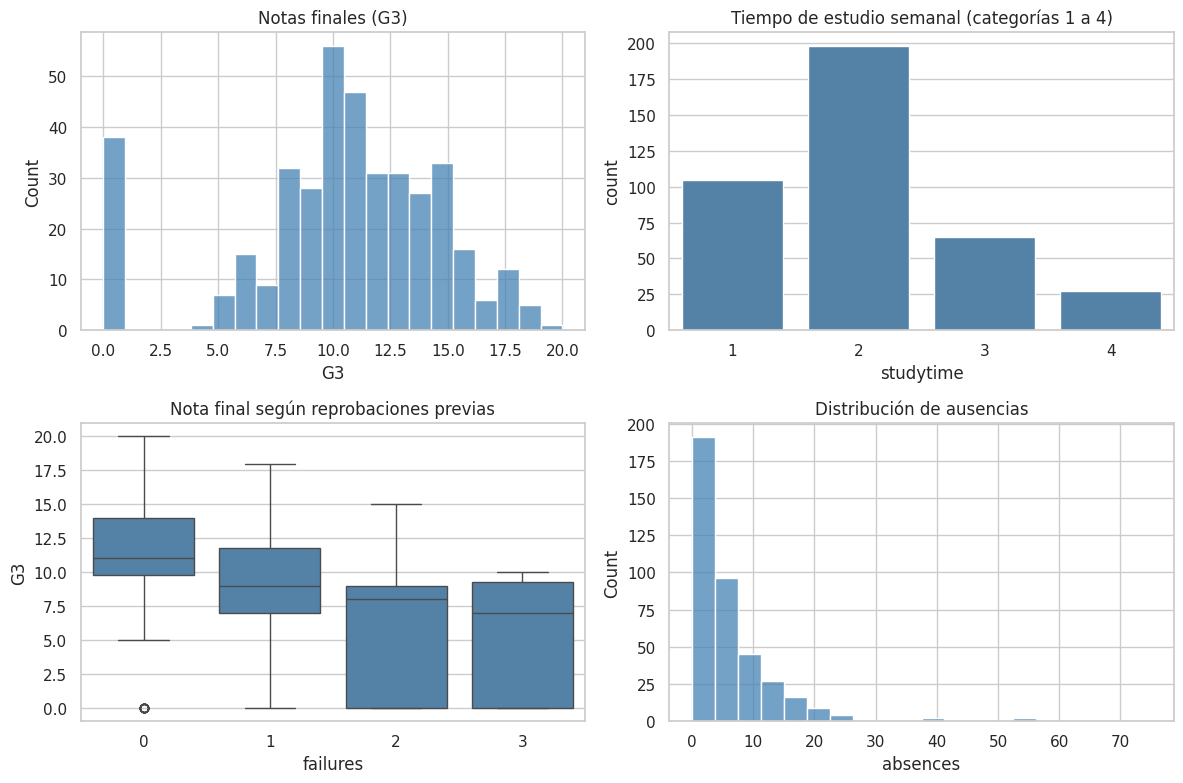

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df_original['G3'], bins=21, kde=False, color='steelblue', ax=ax[0, 0]); ax[0, 0].set_title('Notas finales (G3)')
sns.countplot(data=df_original, x='studytime', color='steelblue', ax=ax[0, 1]); ax[0, 1].set_title('Tiempo de estudio semanal (categorías 1 a 4)')
sns.boxplot(data=df_original, x='failures', y='G3', color='steelblue', ax=ax[1, 0]); ax[1, 0].set_title('Nota final según reprobaciones previas')
sns.histplot(df_original['absences'], bins=20, color='steelblue', ax=ax[1, 1]); ax[1, 1].set_title('Distribución de ausencias')
plt.tight_layout(); plt.show()

### Tres hallazgos expresados de forma sencilla
1. El promedio de la nota final es **10,42/20** y cerca del **67,1 %** alcanza la nota de aprobación de 10 puntos.
2. `G2` (**r ≈ 0,905**) y `G1` (**r ≈ 0,801**) están fuertemente relacionadas con `G3`, aunque esas notas podrían no existir cuando la institución desea intervenir temprano.
3. Los estudiantes sin reprobaciones previas obtienen cerca de **11,25 puntos** en promedio, frente a **7,27 puntos** entre quienes sí tuvieron reprobaciones. Esta diferencia es una asociación del dataset, no demuestra causalidad.

## Registro de aporte personal

- **Qué revisé o cambié:** (describir antes de hacer el commit).
- **Qué aprendí:** (escribir con mis propias palabras).
- **Qué resultado comprobé:** (poner un valor concreto de la ejecución).

### Uso de herramientas
El material de partida fue preparado con asistencia de ChatGPT. Cada estudiante debe declarar cualquier herramienta utilizada y describir su aportación efectiva.